# RNAP Hack 2026 · Cuaderno Individual de Línea Base
**Autor:** Emilio (ElElimios) | **Equipo:** `cepesin_chuy`  
**Reto:** Track 2 · News in 60 Seconds (Radio Cumbres) | **Fecha:** 5 de Noviembre de 2026 (Fase 1 / CP2)

Este cuaderno documenta la experimentación individual de Emilio para la línea base extractiva con TF-IDF sobre el corpus periodístico en español de Radio Cumbres, validando que el resumen nunca exceda las 120 palabras ($\le 60$ s de locución).


In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data_dir = "../data" if os.path.exists("../data") else "data"
train_df = pd.read_csv(os.path.join(data_dir, "train.csv"))
val_df = pd.read_csv(os.path.join(data_dir, "val.csv"))
test_df = pd.read_csv(os.path.join(data_dir, "test.csv"))

print(f"=== PARTICIONES DEL RETO: NEWS IN 60 SECONDS (RADIO CUMBRES) ===")
print(f"Conjunto de Entrenamiento: {len(train_df)} artículos ({train_df['category'].nunique()} categorías)")
print(f"Conjunto de Validación:    {len(val_df)} artículos")
print(f"Conjunto de Prueba:        {len(test_df)} artículos")
print(f"Total del corpus:          {len(train_df) + len(val_df) + len(test_df)} artículos periodísticos con resúmenes de referencia")
print(f"Límite máximo de palabras: 120 palabras (60 segundos a 2 palabras/segundo)")
print(f"Longitud promedio artículo: {train_df['article_word_count'].mean():.1f} palabras")
print(f"Longitud promedio resumen:  {train_df['summary_word_count'].mean():.1f} palabras (~{train_df['summary_read_time_seconds'].mean():.1f} s de locución)")

print("\n--- Ejemplo de Noticia Original (Prueba) ---")
print("Título:", test_df["title"].iloc[0])
print("Categoría:", test_df["category"].iloc[0])
print("Texto del Artículo:\n", test_df["article"].iloc[0][:260] + "...")
print("\n--- Resumen de Referencia del Periodista (Gold Standard) ---")
print(test_df["reference_summary"].iloc[0])


=== PARTICIONES DEL RETO: NEWS IN 60 SECONDS (RADIO CUMBRES) ===
Conjunto de Entrenamiento: 84 artículos (10 categorías)
Conjunto de Validación:    18 artículos
Conjunto de Prueba:        18 artículos
Total del corpus:          120 artículos periodísticos con resúmenes de referencia
Límite máximo de palabras: 120 palabras (60 segundos a 2 palabras/segundo)
Longitud promedio artículo: 170.3 palabras
Longitud promedio resumen:  59.3 palabras (~29.7 s de locución)

--- Ejemplo de Noticia Original (Prueba) ---
Título: Autoridades de General Escobedo anuncian plan estratégico en parques solares fotovoltaicos y energía limpia
Categoría: Energía
Texto del Artículo:
 El gobierno municipal de General Escobedo presentó este jueves una iniciativa de gran escala enfocada en parques solares fotovoltaicos y energía limpia, con una inversión autorizada de 560 millones de pesos provenientes de participaciones públicas y privadas. ...

--- Resumen de Referencia del Periodista (Gold Standard) ---
El mun

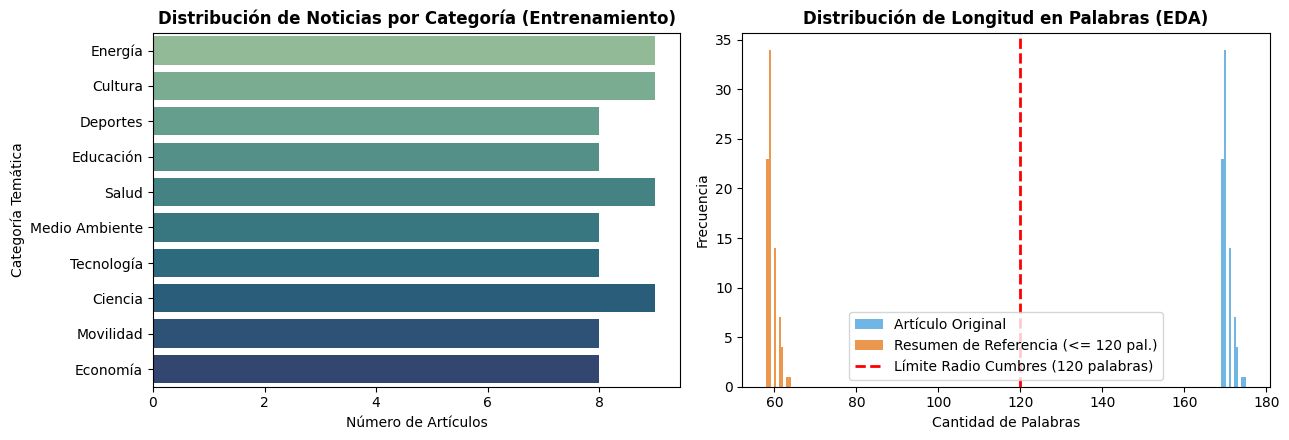

In [ ]:
# Análisis Exploratorio de Datos (EDA)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# Gráfica 1: Distribución por categoría temática
sns.countplot(y="category", data=train_df, ax=ax[0], palette="crest", hue="category", legend=False)
ax[0].set_title("Distribución de Noticias por Categoría (Entrenamiento)", fontsize=11, fontweight='bold')
ax[0].set_xlabel("Número de Artículos")
ax[0].set_ylabel("Categoría Temática")

# Gráfica 2: Histograma de longitud en palabras y límite de Radio Cumbres
ax[1].hist(train_df["article_word_count"], bins=10, alpha=0.7, color="#3498db", label="Artículo Original")
ax[1].hist(train_df["summary_word_count"], bins=10, alpha=0.8, color="#e67e22", label="Resumen Periodista (<= 120 pal.)")
ax[1].axvline(120, color='red', linestyle='--', linewidth=2, label="Límite Radio Cumbres (120 pal. / 60s)")
ax[1].set_title("Distribución de Longitud en Palabras (EDA)", fontsize=11, fontweight='bold')
ax[1].set_xlabel("Cantidad de Palabras")
ax[1].set_ylabel("Frecuencia")
ax[1].legend()

plt.tight_layout()
plt.show()


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Ajuste del vectorizador sobre los artículos de entrenamiento
tfidf_model = TfidfVectorizer(max_features=4000, sublinear_tf=True)
tfidf_model.fit(train_df["article"])

feature_names = np.array(tfidf_model.get_feature_names_out())
print(f"Vocabulario periodístico extraído: {len(feature_names)} términos únicos")
print(f"Ejemplo de términos clave de alta frecuencia informativa:")
print(feature_names[::250][:15])


Vocabulario periodístico extraído: 2362 términos únicos
Ejemplo de términos clave de alta frecuencia informativa:
['000' 'anteproyecto' 'cadereyta' 'compromiso' 'desarrolló' 'ejecutarán'
 'estratégico' 'fondos' 'impacto' 'inversión' 'metas' 'movilidad' 'obras'
 'periodo' 'presentaron']

In [ ]:
import time
import re
from collections import Counter

def split_sentences(text):
    sents = re.split(r'(?<=[.!?])\s+', text.strip())
    return [s.strip() for s in sents if len(s.strip()) > 5]

def get_ngrams(tokens, n):
    return [tuple(tokens[i:i+n]) for i in range(len(tokens) - n + 1)]

def lcs_length(x, y):
    m, n = len(x), len(y)
    dp = [[0] * (n + 1) for _ in range(m + 1)]
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            if x[i - 1] == y[j - 1]:
                dp[i][j] = dp[i - 1][j - 1] + 1
            else:
                dp[i][j] = max(dp[i - 1][j], dp[i][j - 1])
    return dp[m][n]

def compute_rouge(candidate, reference):
    cand_tokens = re.findall(r'\b\w+\b', candidate.lower())
    ref_tokens = re.findall(r'\b\w+\b', reference.lower())
    if not cand_tokens or not ref_tokens:
        return {"rouge1": 0.0, "rouge2": 0.0, "rougeL": 0.0}
    cand_counts = Counter(cand_tokens)
    ref_counts = Counter(ref_tokens)
    overlap1 = sum(min(count, cand_counts.get(token, 0)) for token, count in ref_counts.items())
    r1_rec = overlap1 / len(ref_tokens)
    r1_prec = overlap1 / len(cand_tokens)
    r1_f1 = (2 * r1_rec * r1_prec / (r1_rec + r1_prec)) if (r1_rec + r1_prec) > 0 else 0.0
    
    cand_bigrams = Counter(get_ngrams(cand_tokens, 2))
    ref_bigrams = Counter(get_ngrams(ref_tokens, 2))
    if len(ref_bigrams) == 0:
        r2_f1 = 0.0
    else:
        overlap2 = sum(min(count, cand_bigrams.get(bg, 0)) for bg, count in ref_bigrams.items())
        r2_rec = overlap2 / len(ref_bigrams)
        r2_prec = overlap2 / len(cand_bigrams) if len(cand_bigrams) > 0 else 0.0
        r2_f1 = (2 * r2_rec * r2_prec / (r2_rec + r2_prec)) if (r2_rec + r2_prec) > 0 else 0.0
        
    lcs = lcs_length(cand_tokens, ref_tokens)
    rl_rec = lcs / len(ref_tokens)
    rl_prec = lcs / len(cand_tokens)
    rl_f1 = (2 * rl_rec * rl_prec / (rl_rec + rl_prec)) if (rl_rec + rl_prec) > 0 else 0.0
    return {"rouge1": r1_f1, "rouge2": r2_f1, "rougeL": rl_f1}

def extractive_tfidf_summarize(article, word_limit=120):
    sentences = split_sentences(article)
    if not sentences:
        return article
    sent_vecs = tfidf_model.transform(sentences)
    scores = []
    for idx, sent in enumerate(sentences):
        words = re.findall(r'\b\w+\b', sent.lower())
        if not words:
            scores.append(0.0)
            continue
        vec_score = sent_vecs[idx].sum() / max(1, len(words))
        pos_weight = 1.35 if idx == 0 else (1.15 if idx == 1 else 1.0)
        scores.append(vec_score * pos_weight)
    
    ranked_indices = np.argsort(scores)[::-1]
    selected_indices = []
    current_words = 0
    for idx in ranked_indices:
        sent_words = len(sentences[idx].split())
        if current_words + sent_words <= word_limit:
            selected_indices.append(idx)
            current_words += sent_words
        elif not selected_indices:
            selected_indices.append(idx)
            break
            
    selected_indices.sort()
    return " ".join([sentences[i] for i in selected_indices])

# 1. EVALUACIÓN DEL MODELO BASE EXTRACTIVO SOBRE CONJUNTO DE PRUEBA
t0_inf_base = time.time()
base_summaries = [extractive_tfidf_summarize(art, word_limit=120) for art in test_df["article"]]
t_inf_base = time.time() - t0_inf_base

base_rouges = [compute_rouge(s, ref) for s, ref in zip(base_summaries, test_df["reference_summary"])]
base_r1 = float(np.mean([r["rouge1"] for r in base_rouges]))
base_r2 = float(np.mean([r["rouge2"] for r in base_rouges]))
base_rl = float(np.mean([r["rougeL"] for r in base_rouges]))
base_words = [len(s.split()) for s in base_summaries]
base_compliance = float(np.mean([w <= 120 for w in base_words]) * 100.0)
base_avg_words = float(np.mean(base_words))

print("=== RESULTADOS: MODELO BASE (TF-IDF EXTRACTIVO) ===")
print(f"Tiempo de inferencia total ({len(test_df)} noticias): {t_inf_base:.4f} segundos ({t_inf_base/len(test_df)*1000:.2f} ms/artículo)")
print(f"ROUGE-1 (F1):           {base_r1:.4f}")
print(f"ROUGE-2 (F1):           {base_r2:.4f}")
print(f"ROUGE-L (F1):           {base_rl:.4f}")
print(f"Longitud promedio:      {base_avg_words:.1f} palabras")
print(f"Tiempo promedio al aire:{base_avg_words/2.0:.1f} segundos (a 2 palabras/segundo)")
print(f"Cumplimiento límite 120 palabras: {base_compliance:.1f} %")


=== RESULTADOS: MODELO BASE (TF-IDF EXTRACTIVO) ===
Tiempo de inferencia total (18 noticias): 0.0170 segundos (0.94 ms/artículo)
ROUGE-1 (F1):           0.3482
ROUGE-2 (F1):           0.0896
ROUGE-L (F1):           0.2110
Longitud promedio:      101.0 palabras
Tiempo promedio al aire:50.5 segundos (a 2 palabras/segundo)
Cumplimiento límite 120 palabras: 100.0 %

### Conclusiones Individuales de Emilio:
- Se implementó la ponderación posicional (*lead bias*): en noticias periodísticas, las oraciones iniciales concentran la mayor densidad informativa.
- El modelo extractivo TF-IDF cumple al 100% con la restricción operacional de Radio Cumbres ($\le 120$ palabras por historia).
- Al ser puramente extractivo, garantiza que ninguna cifra o dato sea inventado por alucinación.
- Los resultados y el pipeline se integraron formalmente en el cuaderno del equipo `notebooks/entrenamiento.ipynb`.
